# v104 BEM discretisation: grid spacing, domain and kernel on smooth Hertz contacts

**Question.** Which grid spacing `h`, domain half-length and SlipPY kernel give a stated error in the
approach and the peak pressure of a smooth Hertz point contact, solved through `slippy_bridge`? The answer
is the grid rule this repository uses (v102, v103, Part C of R2, s101).

**Systems.** v101's ball (12.7 mm) on a flat and an ellipsoid (R_x 10 mm, R_y 50 mm) on a flat, steel,
500 N, load control. **References.** r02 Hertz (through v101 `reference`); the grid studies of Polonsky
and Keer (1999, PDF p. 9-10) and Muser (2014, PDF p. 7).

**Criteria (README section 6, fixed before the run).** D1: spatial kernel, approach and p0 change less
than 0.05 % against the largest domain. L1: Polonsky-Keer `eps_r < 1/M` where `M >= 64` (their range).
L3: Muser's rule (`h = a/32`, cell `8a`): contact area from a fit of the pressure profile within 0.1 %.
Recorded: every error of the sweeps, the order of `eps_p`, the frequency kernel's domain change.

In [1]:
from IPython.display import Image, display
from axisforge.outputs._format import format_table

from studies.v100_dry_contact.v104_bem_discretisation import study

out = study.run()

## 1. Grid-spacing sweep (spatial kernel at half-length 2, frequency kernel at 4)

          contact     kernel    b/h  span  n_x   n_y  delta [%]  p0 [%]   b [%]  eps_r [%]  eps_p [%]  area fit [%]  t [s]
-----------------  ---------  -----  ----  ---  ----  ---------  ------  ------  ---------  ---------  ------------  -----
     ball_on_flat    spatial    4.5  2.00   20    20     -0.316  +0.126  -1.279      4.282      2.323        -1.701    0.3
     ball_on_flat    spatial    9.0  2.00   38    38     -0.012  +0.099  +0.449      1.409      1.035        +0.320    0.2
     ball_on_flat    spatial   18.0  2.00   74    74     +0.004  +0.035  +0.255      0.873      0.427        +0.094    0.5
     ball_on_flat    spatial   36.0  2.00  146   146     +0.011  +0.021  +0.171      0.101      0.134        +0.014    1.0
     ball_on_flat    spatial   71.9  2.00  290   290     +0.012  +0.018  +0.137      0.068      0.061        -0.013    2.3
     ball_on_flat  frequency    4.5  4.01   38    38     -1.080  -0.050  -0.793      4.282      1.969        -1.384    0.1
     ball_on_fla

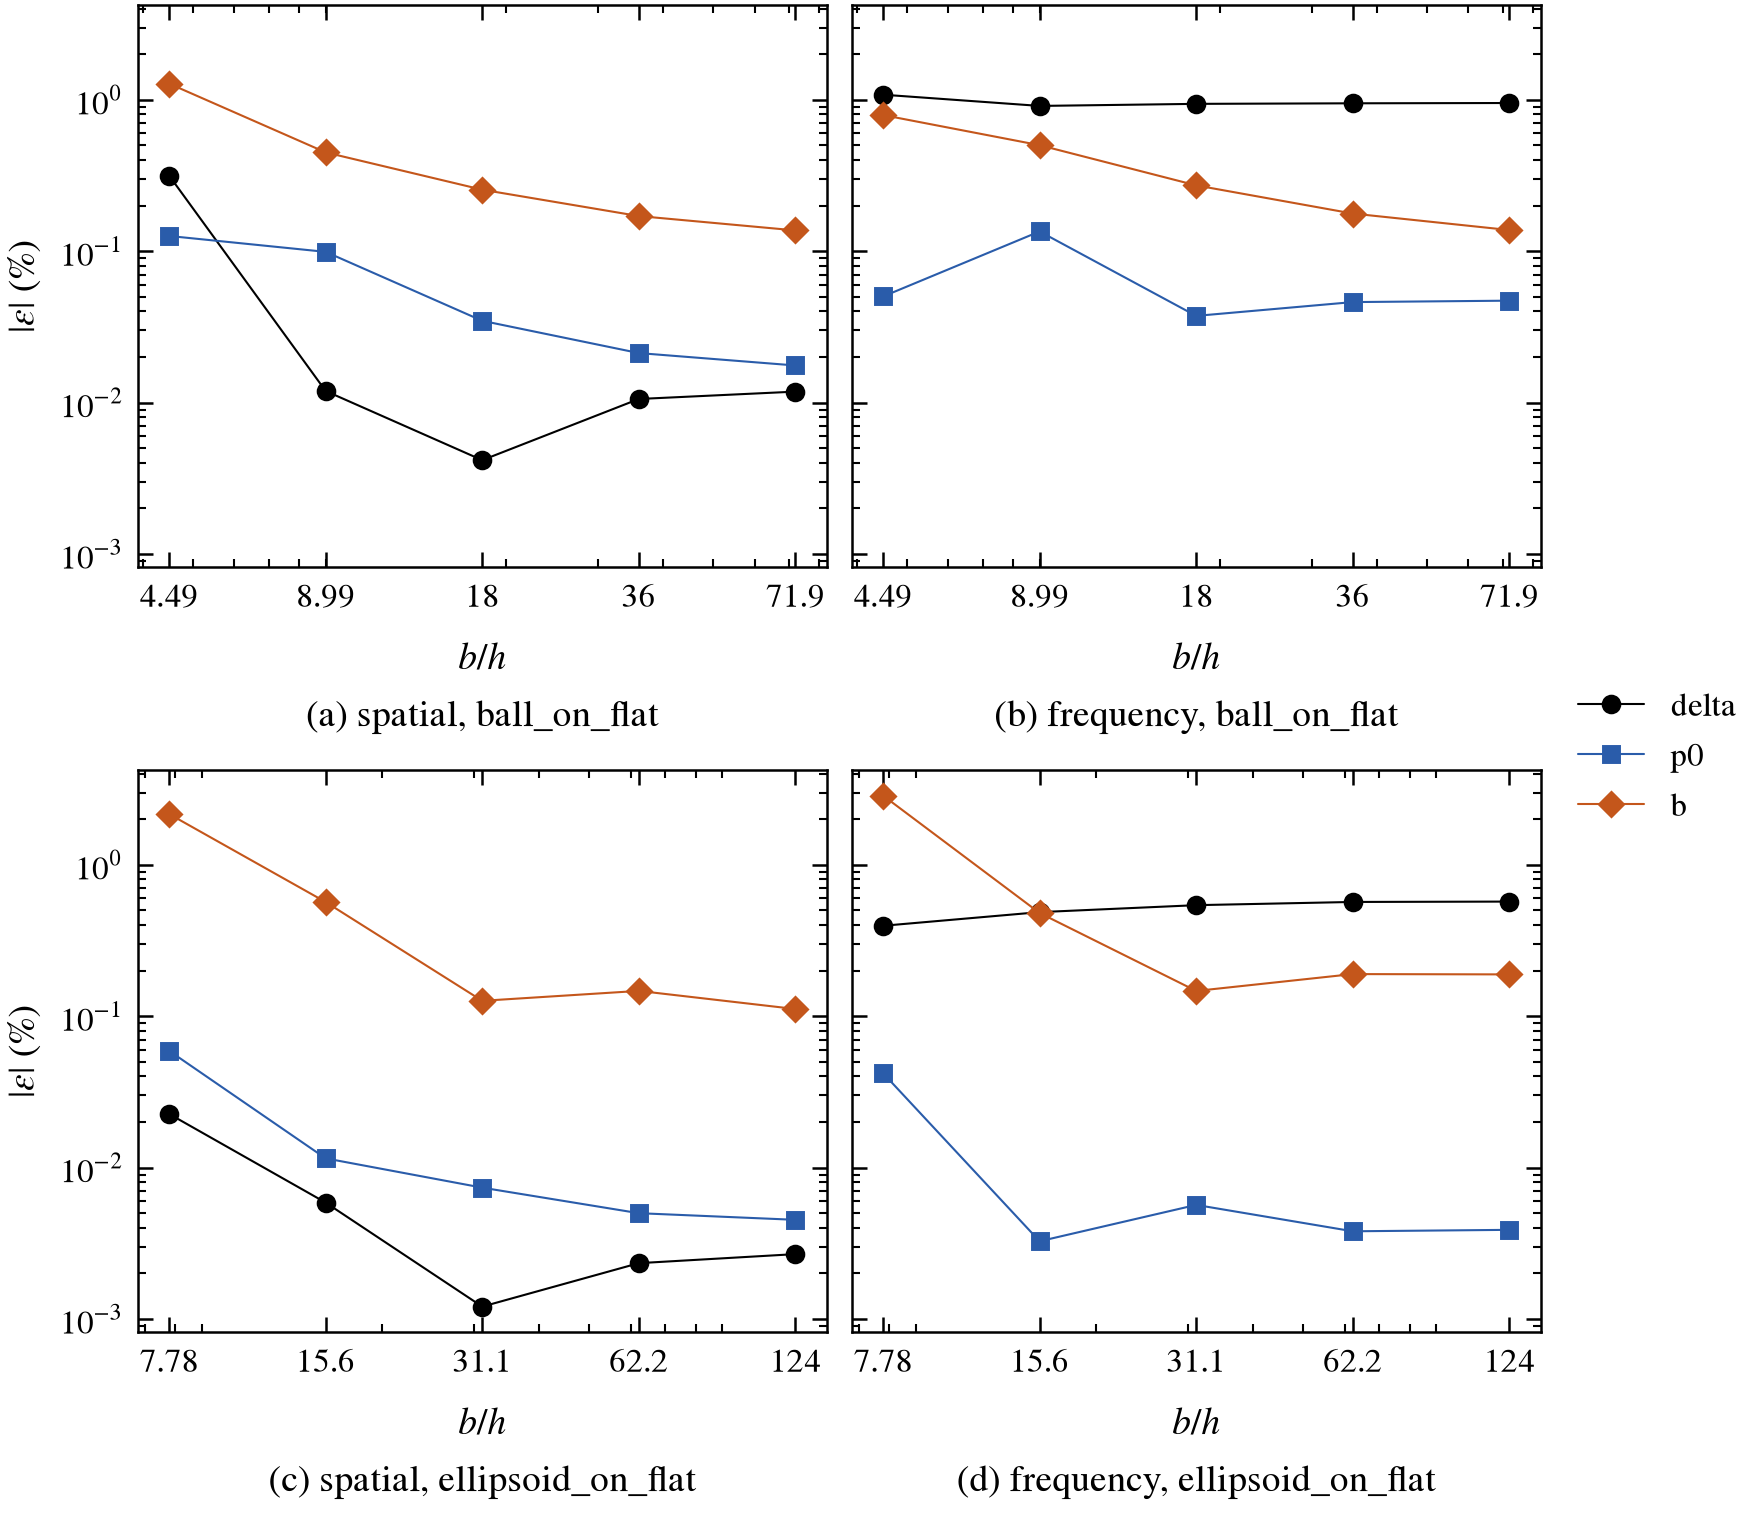

In [2]:
cols = (("label", "contact", "s"), ("kernel", "kernel", "s"), ("b_over_h", "b/h", ".1f"), ("span_x", "span", ".2f"),
        ("n_x", "n_x", "d"), ("n_y", "n_y", "d"), ("err_delta", "delta [%]", "+.3f", 100.0),
        ("err_p0", "p0 [%]", "+.3f", 100.0), ("err_b", "b [%]", "+.3f", 100.0), ("eps_r", "eps_r [%]", ".3f", 100.0),
        ("eps_p", "eps_p [%]", ".3f", 100.0), ("err_area_fit", "area fit [%]", "+.3f", 100.0),
        ("solve_time_s", "t [s]", ".1f"))
print(format_table(cols, [r for r in out["check"] if r["sweep"] == "h"]))
display(Image(filename=str(out["figures"][0])))

## 2. Domain sweep (`b/h` 16 asked) and D1

          contact     kernel   b/h  span  n_x   n_y  delta [%]  p0 [%]   b [%]  eps_r [%]  eps_p [%]  area fit [%]  t [s]
-----------------  ---------  ----  ----  ---  ----  ---------  ------  ------  ---------  ---------  ------------  -----
     ball_on_flat    spatial  18.0  1.28   48    48     +0.004  +0.035  +0.255      0.873      0.427        +0.094    0.6
     ball_on_flat    spatial  18.0  1.50   56    56     +0.004  +0.035  +0.255      0.873      0.427        +0.094    0.4
     ball_on_flat    spatial  18.0  2.00   74    74     +0.004  +0.035  +0.255      0.873      0.427        +0.094    0.1
     ball_on_flat    spatial  18.0  4.01  146   146     +0.004  +0.035  +0.255      0.873      0.427        +0.094    0.2
     ball_on_flat    spatial  18.0  8.01  290   290     +0.004  +0.035  +0.255      0.873      0.427        +0.094    0.9
     ball_on_flat  frequency  18.0  1.28   48    48     -2.281  +0.864  +0.168      0.089      1.005        -0.771    0.1
     ball_on_flat  frequ

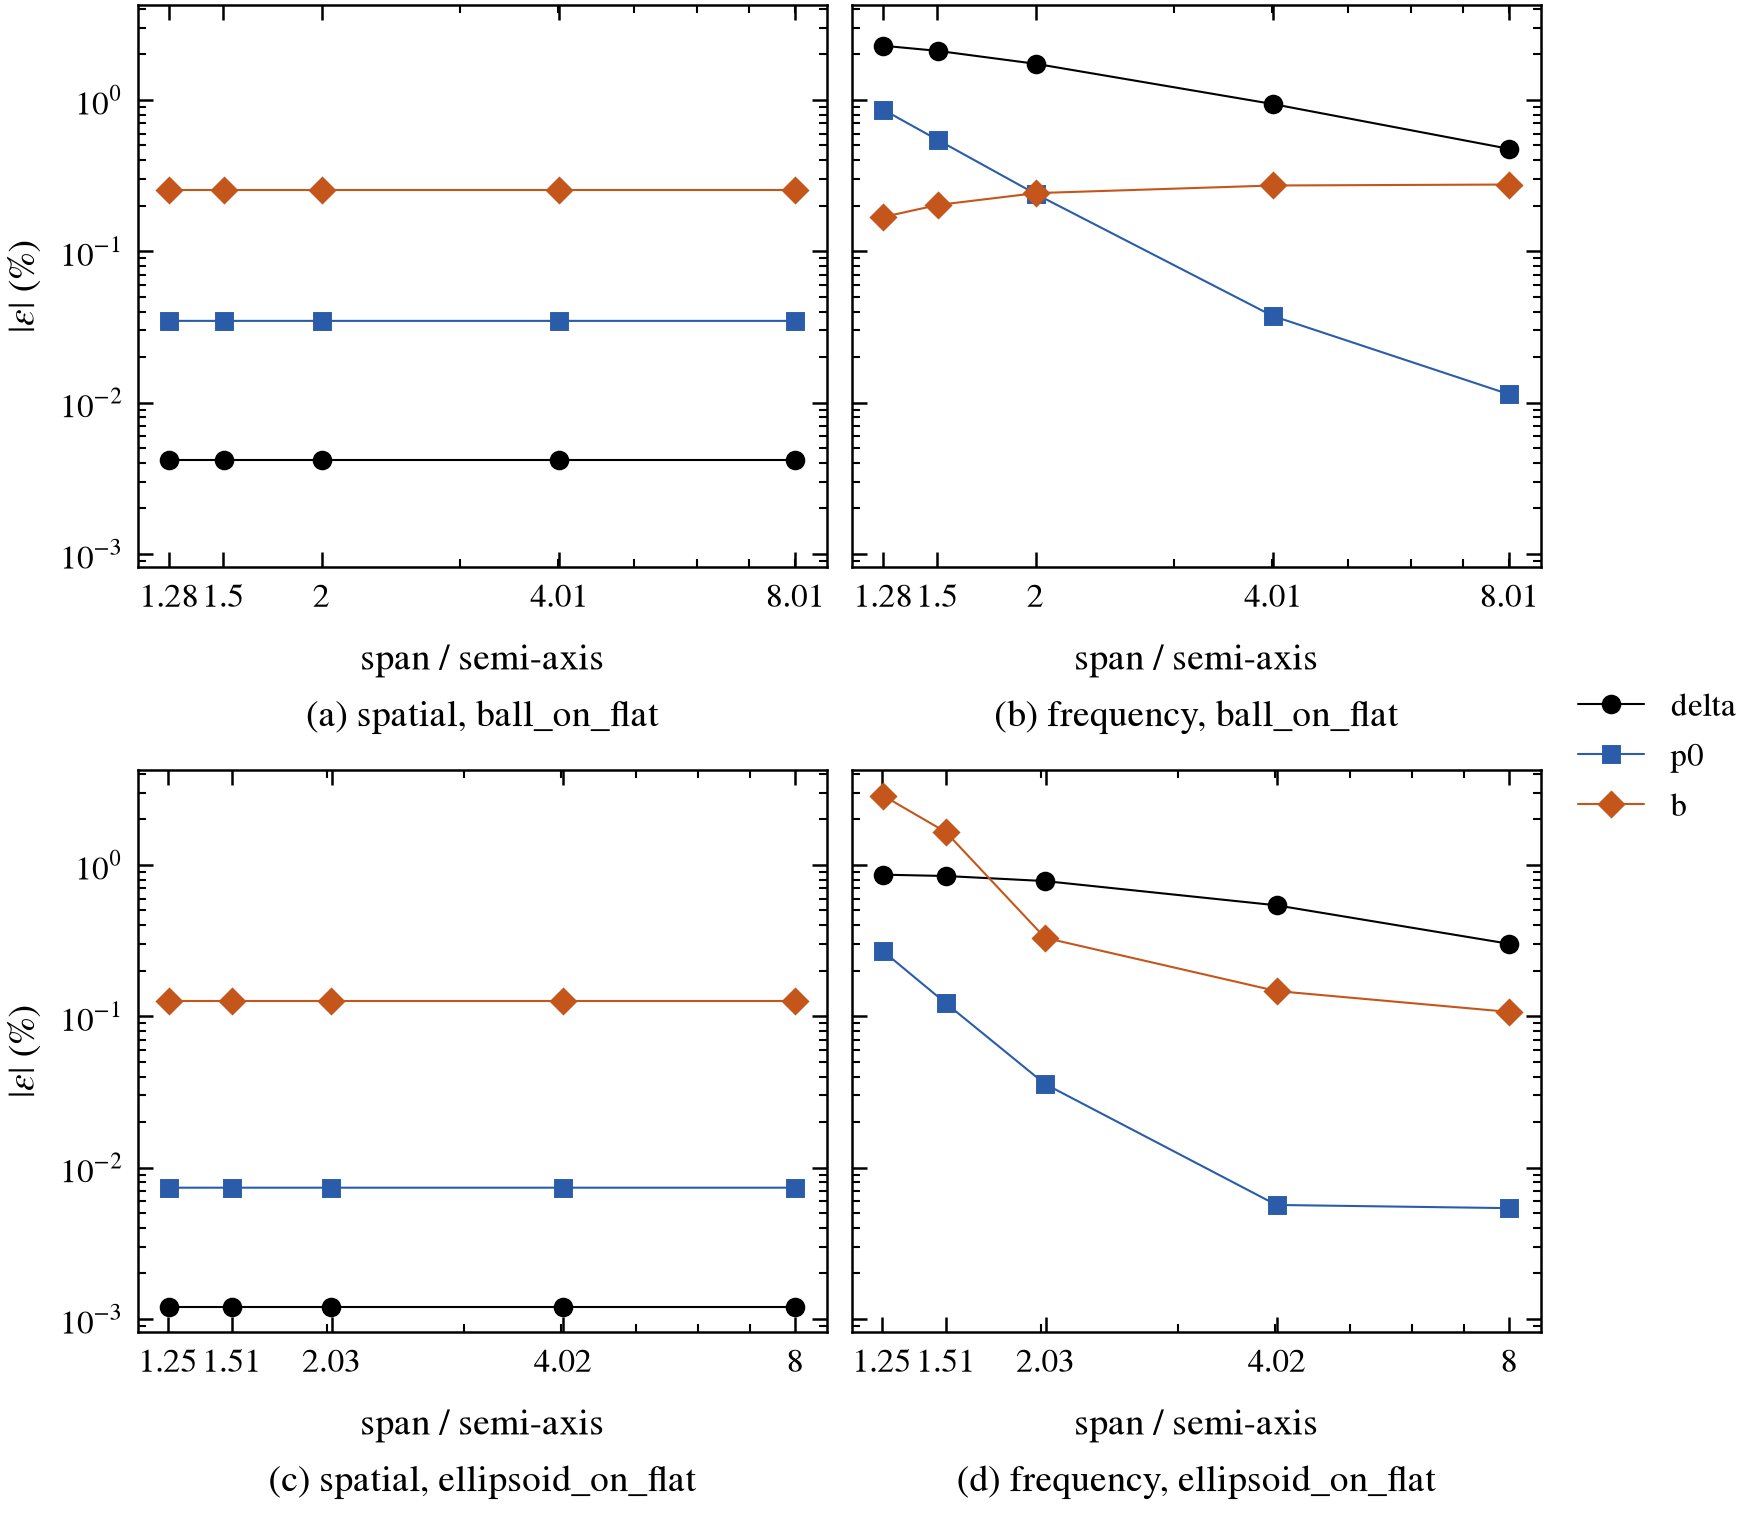

In [3]:
print(format_table(cols, [r for r in out["check"] if r["sweep"] == "span"]))
print()
print(format_table((("id", "id", "s"), ("label", "contact", "s"), ("kernel", "kernel", "s"), ("span_x", "span", ".2f"),
                    ("value", "change [%]", ".4f", 100.0), ("limit", "tol [%]", ".3f", 100.0),
                    ("verdict", "verdict", "s")), [r for r in out["judged"] if r["id"] == "D1"]))
display(Image(filename=str(out["figures"][1])))

## 3. The published grid studies (circle)

In [4]:
print(format_table((("id", "id", "s"), ("kernel", "kernel", "s"), ("M", "M", ".1f"), ("span_x", "span", ".2f"),
                    ("quantity", "quantity", "s"), ("value", "value", ".5f"), ("limit", "limit", ".5f"),
                    ("verdict", "verdict", "s")), [r for r in out["judged"] if r["id"] != "D1"]))

id     kernel      M  span                           quantity     value    limit  verdict
--  ---------  -----  ----  ---------------------------------  --------  -------  -------
L1    spatial    9.0  2.00                              eps_r   0.04282  0.11126   RECORD
L1    spatial   18.0  2.00                              eps_r   0.01409  0.05563   RECORD
L1    spatial   36.0  2.00                              eps_r   0.00873  0.02781   RECORD
L1    spatial   71.9  2.00                              eps_r   0.00101  0.01391     PASS
L1    spatial  143.8  2.00                              eps_r   0.00068  0.00695     PASS
L2    spatial  143.8  2.00  order of eps_p (two finest grids)   1.12255  1.50000   RECORD
L3    spatial   71.9  4.01                       err_area_fit   0.00014  0.00100   RECORD
L1  frequency    9.0  4.01                              eps_r   0.04282  0.11126   RECORD
L1  frequency   18.0  4.01                              eps_r   0.01409  0.05563   RECORD
L1  freque

## 4. The grid rule: coarsest `b/h` (asked and rounded down to a power of two in metres) from which the
error stays within the stated value on every finer grid of the sweep

In [5]:
print(format_table((("label", "contact", "s"), ("kernel", "kernel", "s"), ("quantity", "quantity", "s"),
                    ("tol", "error [%]", ".2f", 100.0), ("span_x", "span", ".2f"), ("b_over_h_min", "b/h min", ".2f"),
                    ("reached", "reached", "s")), out["grid_rule"]))
judged = [r for r in out["judged"] if r["verdict"] != "RECORD"]
print(f"judged {len(judged)}, MISS {sum(r['verdict'] == 'MISS' for r in judged)}")

          contact     kernel  quantity  error [%]  span  b/h min  reached
-----------------  ---------  --------  ---------  ----  -------  -------
     ball_on_flat    spatial     delta       0.50  2.00     4.49      yes
     ball_on_flat    spatial        p0       0.50  2.00     4.49      yes
     ball_on_flat    spatial     delta       0.10  2.00     8.99      yes
     ball_on_flat    spatial        p0       0.10  2.00     8.99      yes
     ball_on_flat  frequency     delta       0.50  4.01        -       no
     ball_on_flat  frequency        p0       0.50  4.01     4.49      yes
     ball_on_flat  frequency     delta       0.10  4.01        -       no
     ball_on_flat  frequency        p0       0.10  4.01    17.98      yes
ellipsoid_on_flat    spatial     delta       0.50  2.06     7.78      yes
ellipsoid_on_flat    spatial        p0       0.50  2.06     7.78      yes
ellipsoid_on_flat    spatial     delta       0.10  2.06     7.78      yes
ellipsoid_on_flat    spatial        p0